# Mixing products on one grid: Sentinel-2, Sentinel-3, Copernicus DEM and ERA5

Four products made by four different instruments or models, at four different resolutions, are combined here cell by cell, **without any regridding**. This works because GRID4EARTH puts them all on the same grid: HEALPix, nested indexing, on the WGS84 ellipsoid. On that grid

- a cell id is a place: the same id means the same piece of ground in every product,
- the levels are nested: the parent of a cell is its id shifted right by two bits per level.

So mixing products comes down to integer arithmetic on cell ids. The notebook shows how to

1. **find** the four stores that cover one place,
2. **read** the same cells from each of them and put them in one Xarray dataset,
3. **plot** them side by side,
4. **combine** them: Sentinel-2 against Sentinel-3, vegetation against elevation, satellite overpasses against the weather of the day,
5. **zoom in**: the same mix at a finer level.

**The place**: the Chaîne des Puys, a line of about 80 volcanoes west of Clermont-Ferrand (France), with the Puy de Dôme (1465 m) in the middle.

**The data**, all of 2026-08-12 except the elevation:

| Product | What | Native resolution | HEALPix level used here |
|---|---|---|---|
| Sentinel-2B MSI Level-2A | surface reflectance, 10:46 UTC | 10 to 60 m | 15 (≈200 m) and 18 (≈25 m) |
| Sentinel-3A OLCI Level-1 EFR | top-of-atmosphere radiance, 09:58 UTC | 300 m | 15 |
| Copernicus DEM GLO-30 | surface elevation | 30 m | 15 and 18 |
| ERA5 | hourly reanalysis | ≈31 km | 7 (≈50 km) |

Nothing is downloaded beforehand: each step reads only the chunks it needs over HTTPS. The first notebook, *Sentinel-2: find, open, extract and plot at several resolutions*, explains the layout of the Sentinel-2 stores in more detail.

In [1]:
import numpy as np
import xarray as xr
import xdggs  # noqa: F401  (registers the .dggs accessor)
import healpix_geo.nested as hpx
import healpix_plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pystac_client import Client

# The Sentinel-2 reflectance is stored with the codecs of healpix-compress;
# zarr finds them through the package's entry points, so it only needs to be installed.
_ = xr.set_options(display_expand_attrs=False, display_expand_data_vars=False)

## 1. Find the four stores of one place

Three of the four stores are items of the GRID4EARTH STAC catalogue. The same point is searched in their three collections; the `product` asset of an item is the root of its Zarr store.

In [2]:
lon, lat = 2.9644, 45.7722  # summit of the Puy de Dôme
day = "2026-08-12"

catalog = Client.open("https://stac-api.grid4earth.eu")


def find(collection, datetime=None):
    search = catalog.search(
        collections=[collection],
        intersects={"type": "Point", "coordinates": [lon, lat]},
        datetime=datetime,
    )
    return next(search.items())


s2_item = find("converted-healpix-tiled-sentinel-2-l2a-multires", day)
dem_item = find("converted-copernicus-dem-glo-30")
era5_item = find("auxiliary-reanalysis-era5-complete", day)

for item in (s2_item, dem_item, era5_item):
    print(item.assets["product"].href)

https://data.grid4earth.eu/converted-healpix-tiled/sentinel-2-l2a-multires/mean-l20-l12-hcc/S2B_MSIL2A_20260812T104619_R051_O49269_L7_C10993.zarr
https://data.grid4earth.eu/converted/copernicus-dem-glo-30/mean-l18-l8-c8-s6/l5/copernicus-dem-glo-30_L5_C687.zarr
https://data.grid4earth.eu/auxiliary/reanalysis-era5-complete/S00__ADF_ECMWA_20260812T000000_20260812T230000_20261019T071509.zarr


The stores are cut differently, and the cell ids tell how they fit together. The level-7 cell (≈50 km) that contains the summit is

- exactly the area of the Sentinel-2 store (one store per level-7 cell),
- one sixteenth of the elevation store (one store per level-5 cell, its grandparent),
- one cell of ERA5, which is stored at level 7 for the whole globe.

In [3]:
def cell_of(lon, lat, level):
    return int(hpx.lonlat_to_healpix(np.array([lon]), np.array([lat]), depth=level, ellipsoid="WGS84")[0])


area_level = 7
area = cell_of(lon, lat, area_level)

print(f"level-7 cell {area}")
print(f"  Sentinel-2 store: level-{s2_item.properties['g4e:healpix_parent_level']} cell {s2_item.properties['g4e:healpix_parent_cell']}")
print(f"  elevation store:  level-5 cell {area >> 2 * (7 - 5)}  ({dem_item.id})")

level-7 cell 10993
  Sentinel-2 store: level-7 cell 10993
  elevation store:  level-5 cell 687  (converted-copernicus-dem-glo-30_L5_C687)


The Sentinel-3 OLCI radiances of the same morning are cut per level-7 cell too, and each store is named after its cell. They are a trial conversion that is not in the catalogue yet, so the store is opened from its address.

In [4]:
olci_store_level = 7
olci_url = (
    "https://data.grid4earth.eu/trials/tinaok-20261113-olci-tiled/converted/sentinel-3-olci-l1-efr/mean-l15-l12-c7/l7/"
    f"S3A_OL_1_EFR_20260812T095824_R350_O54608_L{olci_store_level}_C{area >> 2 * (7 - olci_store_level)}.zarr"
)
print(olci_url)

https://data.grid4earth.eu/trials/tinaok-20261113-olci-tiled/converted/sentinel-3-olci-l1-efr/mean-l15-l12-c7/l7/S3A_OL_1_EFR_20260812T095824_R350_O54608_L7_C10993.zarr


## 2. Read the same cells from each store

The working level is 15 (≈200 m), close to the 300 m of OLCI. The level-7 cell has 4⁸ = 65,536 children at level 15, and in the nested scheme their ids are consecutive.

**Stores per parent cell.** The Sentinel-2, Sentinel-3 and elevation stores hold *every* cell of their parent, in nested order. The position of a cell inside a level is its id minus the id of the first cell of the store: no search, and only the chunks that hold the cells are read.

In [5]:
def positions(cell, cell_level, level, store_cell=0, store_level=0):
    """Positions, at `level`, of the cells of `cell` (given at `cell_level`) in a dense store.

    The store holds all the cells of `store_cell` (given at `store_level`); the default is a global store.
    """
    first_in_store = store_cell << 2 * (level - store_level)
    start = (cell << 2 * (level - cell_level)) - first_in_store
    return slice(start, start + 4 ** (level - cell_level))


level = 15

s2 = xr.open_dataset(s2_item.assets["product"].href, engine="zarr", group=f"measurements/reflectance/{level}")
s2 = s2.isel(cells=positions(area, area_level, level, store_cell=area, store_level=7))

dem = xr.open_dataset(dem_item.assets["product"].href, engine="zarr", group=f"dem/{level}")
dem = dem.isel(cells=positions(area, area_level, level, store_cell=area >> 4, store_level=5))

olci = xr.open_dataset(olci_url, engine="zarr", group=f"measurements/{level}")
olci = olci.isel(cells=positions(area, area_level, level, store_cell=area >> 2 * (7 - olci_store_level), store_level=olci_store_level))

print(f"Sentinel-2: {s2.sizes['cells']:,} cells, Sentinel-3: {olci.sizes['cells']:,} cells, elevation: {dem.sizes['cells']:,} cells")

Sentinel-2: 65,536 cells, Sentinel-3: 65,536 cells, elevation: 65,536 cells


**A global store.** ERA5 is stored at level 7 for the whole sphere, so the position of a cell is its id. The area is a single ERA5 cell, with 24 hourly values.

In [6]:
era5 = xr.open_dataset(era5_item.assets["product"].href, engine="zarr", group="measurements/oper")
era5 = era5.isel(cells=area).load()
assert int(era5["cell_ids"]) == area

The three level-15 selections come from three stores, cut at two different parent levels, and they carry exactly the same cell ids, in the same order. They can go into one dataset as they are.

In [7]:
assert np.array_equal(s2["cell_ids"].values, dem["cell_ids"].values)
assert np.array_equal(s2["cell_ids"].values, olci["cell_ids"].values)

mix = xr.Dataset(
    {
        "b02": s2["b02"],
        "b03": s2["b03"],
        "b04": s2["b04"],
        "b8a": s2["b8a"],
        "elevation": ("cells", dem["dsm"].values, {"long_name": "surface elevation", "units": "m"}),
        "oa06": ("cells", olci["oa06_radiance"].values, olci["oa06_radiance"].attrs),
        "oa08": ("cells", olci["oa08_radiance"].values, olci["oa08_radiance"].attrs),
        "oa17": ("cells", olci["oa17_radiance"].values, olci["oa17_radiance"].attrs),
    },
    attrs=s2.attrs,
).load()

mix = mix.dggs.decode(convention="zarr")
print(mix.dggs.grid_info)
mix

HealpixInfo(level=15, ellipsoid=Ellipsoid(semimajor_axis=6378137.0, inverse_flattening=298.257223563, name='wgs84'), indexing_scheme='nested')


<xarray.Dataset> Size: 4MB
Dimensions:    (cells: 65536)
Coordinates:
  * cell_ids   (cells) uint64 524kB 720437248 720437249 ... 720502782 720502783
Dimensions without coordinates: cells
Data variables: (8)
Indexes:
    cell_ids  HealpixIndex(level=15, indexing_scheme=nested, kind=pandas)

## 3. Plot them side by side

healpix-plot resamples HEALPix cells onto a regular image grid for matplotlib and cartopy. The four panels show the same 65,536 cells:

- Sentinel-2 in true colour (B04, B03, B02),
- OLCI in false colour (Oa17 865 nm, Oa08 665 nm, Oa06 560 nm): vegetation is red,
- the elevation,
- the vegetation index NDVI = (B8A − B04) / (B8A + B04) from Sentinel-2.

Text(0.5, 0.92, 'One level-7 cell (10993), four views of the same 65,536 level-15 cells')

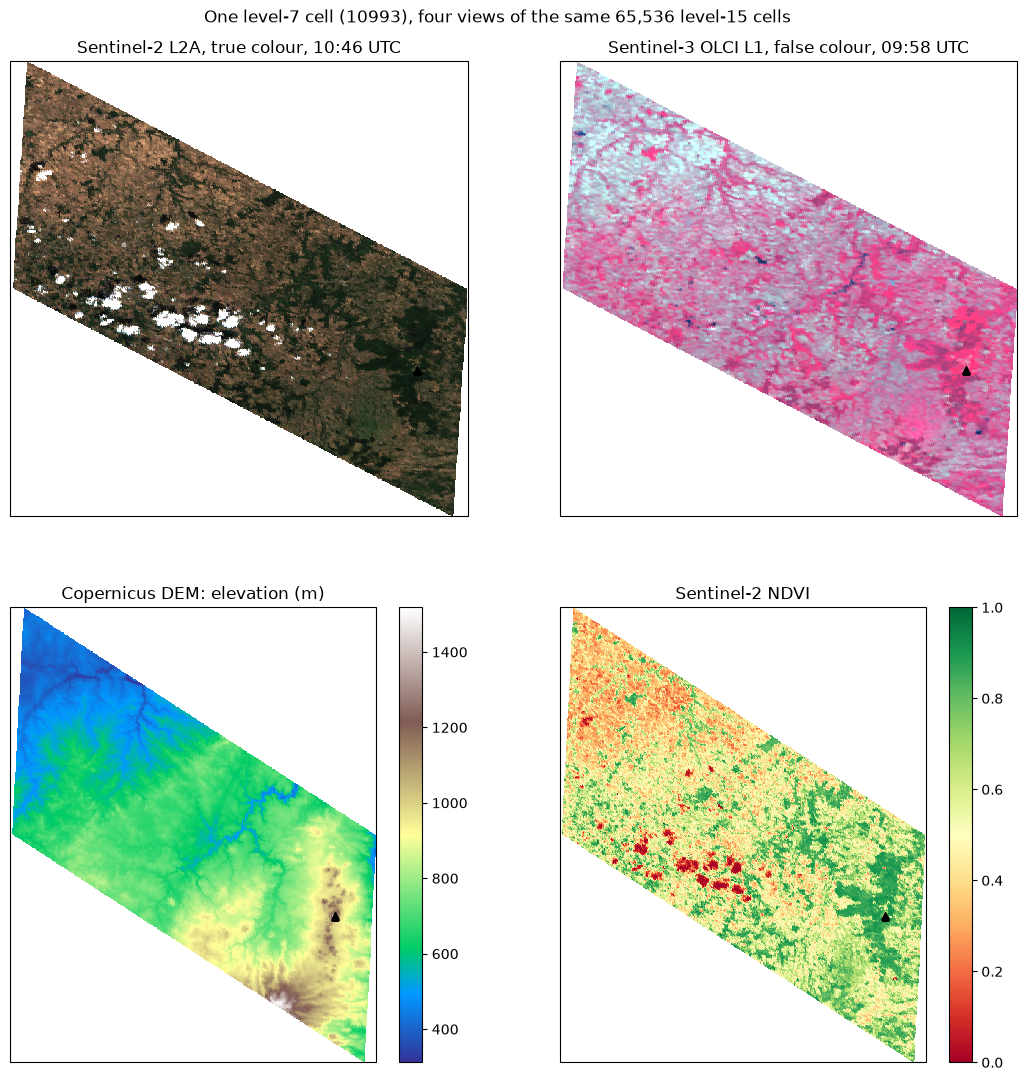

In [8]:
mix["ndvi"] = (mix["b8a"] - mix["b04"]) / (mix["b8a"] + mix["b04"])


def show(cell_ids, data, level, ax, title, **kwargs):
    return healpix_plot.plot(
        np.asarray(cell_ids),
        np.asarray(data),
        healpix_grid=healpix_plot.HealpixGrid(level=level, indexing_scheme="nested", ellipsoid="WGS84"),
        sampling_grid={"shape": 800},
        ax=ax,
        title=title,
        axis_labels="none",
        **kwargs,
    )


def stretch(*bands, gain=None):
    """Stack bands into an RGB image, each scaled by `gain` or by its 99th percentile."""
    scaled = [band * gain if gain else band / np.nanpercentile(band, 99) for band in bands]
    return np.clip(np.stack(scaled, axis=-1), 0, 1)


projection = ccrs.LambertAzimuthalEqualArea(central_longitude=lon, central_latitude=lat)
fig, axes = plt.subplots(2, 2, figsize=(13, 13), subplot_kw={"projection": projection})
ids = mix["cell_ids"].values

show(ids, stretch(mix["b04"], mix["b03"], mix["b02"], gain=3.5), level, axes[0, 0], "Sentinel-2 L2A, true colour, 10:46 UTC")
show(ids, stretch(mix["oa17"], mix["oa08"], mix["oa06"]), level, axes[0, 1], "Sentinel-3 OLCI L1, false colour, 09:58 UTC")
show(ids, mix["elevation"], level, axes[1, 0], "Copernicus DEM: elevation (m)", cmap="terrain", colorbar=True)
show(ids, mix["ndvi"], level, axes[1, 1], "Sentinel-2 NDVI", cmap="RdYlGn", vmin=0, vmax=1, colorbar=True)

for ax in axes.flat:
    ax.plot(lon, lat, "k^", markersize=6, transform=ccrs.PlateCarree())
fig.suptitle(f"One level-7 cell ({area}), four views of the same {mix.sizes['cells']:,} level-{level} cells", y=0.92)

## 4. Combine them

### A mask from a finer level

A few small clouds drifted over the area at the time of the Sentinel-2 overpass. The Sentinel-2 store has a scene classification, stored at level 17 (≈50 m). Each level-15 cell has 16 children at level 17, and they are consecutive, so a `reshape` brings the mask to level 15: a cell is kept when none of its children is cloud or cloud shadow.

In [9]:
scl = xr.open_dataset(s2_item.assets["product"].href, engine="zarr", group="conditions/mask/l2a_classification/17")["scl"]
scl = scl.isel(cells=positions(area, area_level, 17, store_cell=area, store_level=7)).values

cloud_or_shadow = np.isin(scl, [3, 8, 9, 10])  # cloud shadow, cloud (medium, high probability), thin cirrus
mix["clear"] = ("cells", ~cloud_or_shadow.reshape(-1, 4 ** (17 - level)).any(axis=1))
clear = mix.where(mix["clear"])

print(f"{float(mix['clear'].mean()):.1%} of the level-{level} cells are clear")

90.9% of the level-15 cells are clear


### Two satellites, cell for cell

OLCI Oa17 and Sentinel-2 B8A both measure at 865 nm, and Oa08 and B04 at 665 nm. The two instruments passed 48 minutes apart, with different pixel sizes and viewing angles, and the quantities differ (radiance at the top of the atmosphere for OLCI, reflectance at the surface for Sentinel-2). Still, each cell can be compared with itself, because it is the same cell in both.

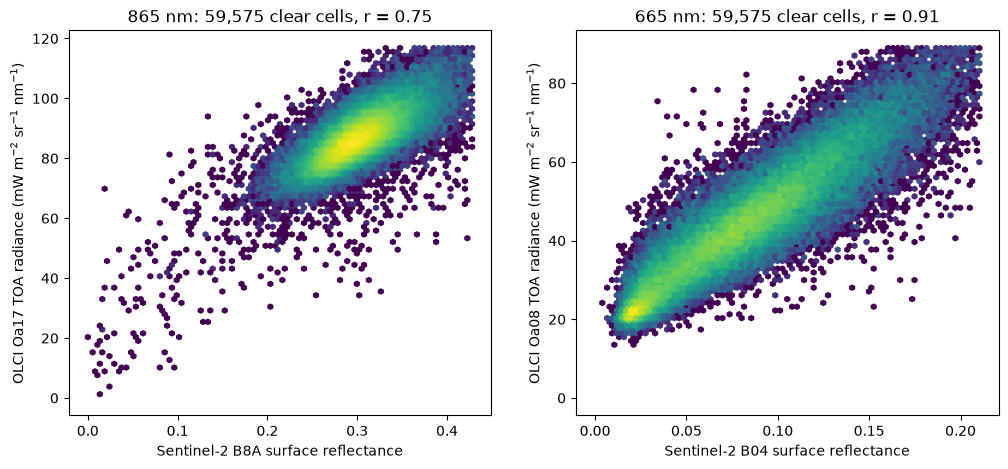

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (s2_band, olci_band, wavelength) in zip(axes, [("b8a", "oa17", 865), ("b04", "oa08", 665)]):
    x, y = clear[s2_band].values, clear[olci_band].values
    valid = np.isfinite(x) & np.isfinite(y)
    r = np.corrcoef(x[valid], y[valid])[0, 1]
    ax.hexbin(x[valid], y[valid], gridsize=80, bins="log", cmap="viridis", extent=(0, np.percentile(x[valid], 99.5), 0, np.percentile(y[valid], 99.5)))
    ax.set(
        xlabel=f"Sentinel-2 {s2_band.upper()} surface reflectance",
        ylabel=f"OLCI {olci_band.capitalize()} TOA radiance (mW m$^{{-2}}$ sr$^{{-1}}$ nm$^{{-1}}$)",
        title=f"{wavelength} nm: {valid.sum():,} clear cells, r = {r:.2f}",
    )

### Vegetation against elevation

The elevation was measured by radar years earlier, the reflectance by Sentinel-2 that morning. On the same cells, grouping one by the other is a plain `groupby`. Each elevation band of 100 m gets the median NDVI of its cells, and the share of the area it covers.

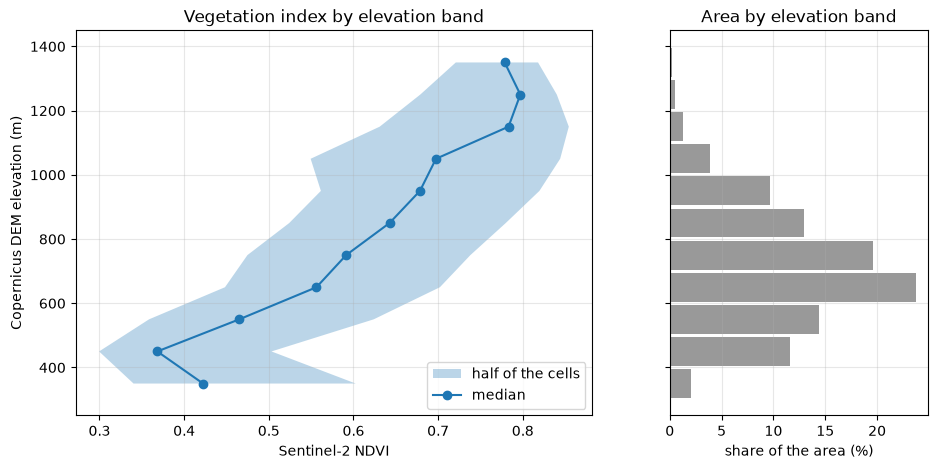

In [11]:
bands = np.arange(300, 1500, 100)
by_elevation = clear["ndvi"].groupby_bins(clear["elevation"], bands)
median = by_elevation.median()
low, high = by_elevation.quantile(0.25), by_elevation.quantile(0.75)
share = by_elevation.count() / int(mix["clear"].sum()) * 100
centre = bands[:-1] + 50

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 5), sharey=True, width_ratios=[2, 1])
left.fill_betweenx(centre, low, high, alpha=0.3, label="half of the cells")
left.plot(median, centre, "o-", label="median")
left.set(xlabel="Sentinel-2 NDVI", ylabel="Copernicus DEM elevation (m)", title="Vegetation index by elevation band")
left.legend(loc="lower right")
left.grid(alpha=0.3)
right.barh(centre, share, height=90, color="0.6")
right.set(xlabel="share of the area (%)", title="Area by elevation band")
right.grid(alpha=0.3)

### The weather of the day

The whole area is one ERA5 cell. Its 24 hourly values place the two overpasses in the day: both happened in the morning, while the air was warming.

At the Sentinel-2 overpass: 30.2 °C, total cloud cover 0.05, total column water vapour 20.4 kg m-2


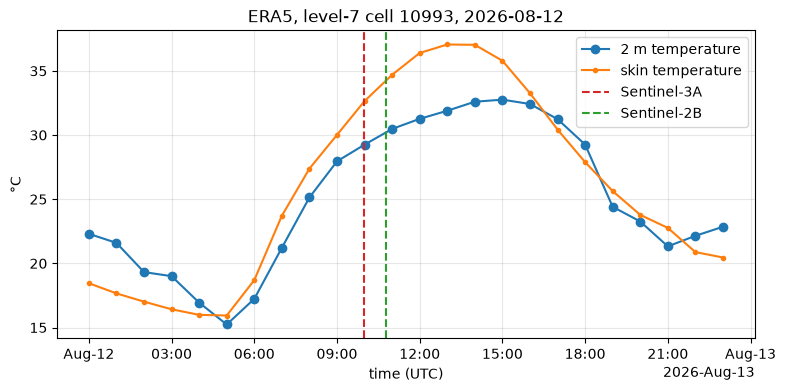

In [12]:
overpass = {
    "Sentinel-3A": np.datetime64("2026-08-12T09:58:24"),
    "Sentinel-2B": np.datetime64(s2_item.datetime.replace(tzinfo=None), "s"),
}

fig, ax = plt.subplots(figsize=(9, 4))
(era5["t2m"] - 273.15).plot(ax=ax, marker="o", label="2 m temperature")
(era5["skt"] - 273.15).plot(ax=ax, marker=".", label="skin temperature")
for (name, time), colour in zip(overpass.items(), ["tab:red", "tab:green"]):
    ax.axvline(time, color=colour, linestyle="--", label=name)
ax.set(xlabel="time (UTC)", ylabel="°C", title=f"ERA5, level-7 cell {area}, {day}")
ax.legend()
ax.grid(alpha=0.3)

at_overpass = era5[["t2m", "tcc", "tcwv"]].interp(time=overpass["Sentinel-2B"])
print(
    f"At the Sentinel-2 overpass: {float(at_overpass['t2m']) - 273.15:.1f} °C, "
    f"total cloud cover {float(at_overpass['tcc']):.2f}, "
    f"total column water vapour {float(at_overpass['tcwv']):.1f} kg m-2"
)

## 5. Zoom in: the same mix at level 18

Sentinel-2 is stored down to level 20 (≈6 m) and the elevation down to level 18 (≈25 m). To look closer, take a smaller region, here the level-10 cell (≈6 km) around the summit, and read both stores at level 18. The code is the same; only the level changes.

Text(0.5, 0.98, 'Level-10 cell 703568 around the Puy de Dôme: 65,536 level-18 cells')

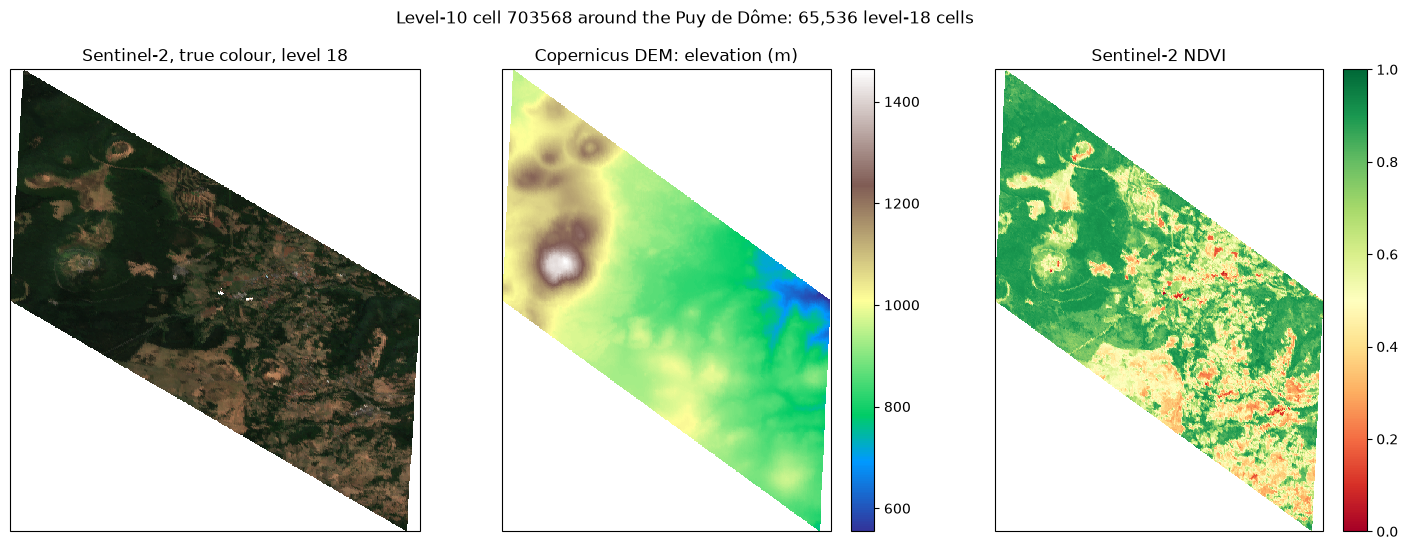

In [13]:
fine, region_level = 18, 10
region = cell_of(lon, lat, region_level)

s2_fine = xr.open_dataset(s2_item.assets["product"].href, engine="zarr", group=f"measurements/reflectance/{fine}")
s2_fine = s2_fine[["b02", "b03", "b04", "b08"]].isel(cells=positions(region, region_level, fine, store_cell=area, store_level=7)).load()

dem_fine = xr.open_dataset(dem_item.assets["product"].href, engine="zarr", group=f"dem/{fine}")
dem_fine = dem_fine.isel(cells=positions(region, region_level, fine, store_cell=area >> 4, store_level=5)).load()

assert np.array_equal(s2_fine["cell_ids"].values, dem_fine["cell_ids"].values)
ids = s2_fine["cell_ids"].values
ndvi = (s2_fine["b08"] - s2_fine["b04"]) / (s2_fine["b08"] + s2_fine["b04"])

fig, axes = plt.subplots(1, 3, figsize=(18, 6), subplot_kw={"projection": projection})
show(ids, stretch(s2_fine["b04"], s2_fine["b03"], s2_fine["b02"], gain=3.5), fine, axes[0], f"Sentinel-2, true colour, level {fine}")
show(ids, dem_fine["dsm"], fine, axes[1], "Copernicus DEM: elevation (m)", cmap="terrain", colorbar=True)
show(ids, ndvi, fine, axes[2], "Sentinel-2 NDVI", cmap="RdYlGn", vmin=0, vmax=1, colorbar=True)
fig.suptitle(f"Level-{region_level} cell {region} around the Puy de Dôme: {ids.size:,} level-{fine} cells", y=0.98)

## What made this simple

- **One grid.** All four products are on HEALPix, nested, on the WGS84 ellipsoid. Each store says so in its `dggs` attribute (the Zarr DGGS convention), which is what xdggs reads.
- **Cell ids are places.** The same cells were read from stores per level-7 cell (Sentinel-2 and Sentinel-3), a store per level-5 cell (elevation) and a global store (ERA5), and they lined up without any interpolation.
- **Levels are nested.** Going from a 50 km ERA5 cell to its 200 m or 25 m children, or back, is a bit shift.

## Next steps

- Change `lon, lat` to any place between 45 and 49°N on the swath of Sentinel-2 relative orbit 51 of that day.
- The other bands, the quality masks and the other ERA5 variables are read the same way.
- The data are test data: the layout and the metadata may still change.